# Face Morphing with Switchable Losses

This Colab demo changes the pixels of a source face so that it becomes more similar to a target face. You can compare three objectives: pixel MSE, a general ResNet encoder, and a face-recognition encoder.

The optimization stores intermediate stages in advance. After it finishes, use the slider to inspect the morphing process.

## 1. Setup

In [ ]:
def ensure_package_installed(package_name, import_name=None, pip_args=None):
    """Install a missing package and return the imported module."""
    import importlib
    import subprocess
    import sys

    import_name = import_name or package_name
    try:
        return importlib.import_module(import_name)
    except ImportError:
        print(f"Installing '{package_name}'...")
        command = [sys.executable, "-m", "pip", "install"]
        command.extend(pip_args or [])
        command.append(package_name)
        subprocess.check_call(command)
        return importlib.import_module(import_name)

# facenet-pytorch 2.6.0 declares an old PyTorch version range. Colab already
# provides a newer, GPU-enabled torch/torchvision pair, so keep those packages
# and install only the pure-Python FaceNet package.
ensure_package_installed(
    'facenet-pytorch==2.6.0',
    'facenet_pytorch',
    pip_args=['--no-deps'],
)

<module 'facenet_pytorch' from '/usr/local/lib/python3.13/dist-packages/facenet_pytorch/__init__.py'>

In [ ]:
from io import BytesIO
import requests
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from facenet_pytorch import InceptionResnetV1
import ipywidgets as widgets
from IPython.display import display, clear_output

def load_image(url):
    """Downloads and returns a PIL image from the given URL."""
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers)
    if response.status_code != 200:
        raise ValueError(f"Failed to download image: {url}")
    try:
        return Image.open(BytesIO(response.content)).convert("RGB")
    except Exception as e:
        raise ValueError(f"Could not open image from {url}. Error: {e}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch version:', torch.__version__)
print('Using device:', device)

# Shared ipywidgets slider style/layout
SLIDER_STYLE = {'description_width': '160px'}
SLIDER_LAYOUT = widgets.Layout(width='520px')

Torch version: 2.11.0+cu130
Using device: cuda


## 2. Configuration
Choose `mse`, `resnet`, or `face`, then run the remaining cells.

In [ ]:
config = {
    'loss_mode': 'face',       # 'mse', 'resnet', or 'face'
    'num_steps': 1500,
    'learning_rate': 0.005,
    'save_every': 5,           # smaller values create more slider stages
    # Encoder losses alone can produce changes that are meaningful to the
    # network but difficult for people to see. This target term makes the
    # visual morph explicit when using 'resnet' or 'face'.
    'lambda_target_mse': 0.05,#0.25,
    'lambda_source_l2': 0.002,
    'lambda_tv': 0.0005,
    'face_input_size': 160,
    'resnet_input_size': 224,
}

valid_modes = {'mse', 'resnet', 'face'}
if config['loss_mode'] not in valid_modes:
    raise ValueError(f"loss_mode must be one of {sorted(valid_modes)}")

## 3. Load the aligned faces

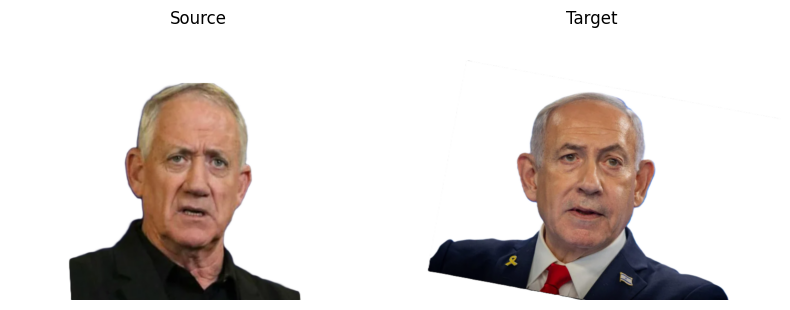

In [ ]:
SOURCE_URL = 'https://www.dropbox.com/scl/fi/qmpsauu95ue9w5rd7wh92/aligned_ref.png?rlkey=ggddheo2ou61xdv06euawcr1r&dl=1'
TARGET_URL = 'https://www.dropbox.com/scl/fi/ysldm42mtx3ur8l7tvw3p/aligned_target.png?rlkey=lyxfzzhsmtr1rq2bvtne4pskk&st=3t1gupde&dl=1'

source_pil = load_image(SOURCE_URL)
target_pil = load_image(TARGET_URL).resize(source_pil.size, Image.Resampling.LANCZOS)

def pil_to_tensor(image):
    array = np.asarray(image, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1).unsqueeze(0).to(device)

source = pil_to_tensor(source_pil)
target = pil_to_tensor(target_pil)

plt.figure(figsize=(8, 4))
for position, (image, title) in enumerate([(source_pil, 'Source'), (target_pil, 'Target')], start=1):
    plt.subplot(1, 2, position)
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Prepare the selected loss
The encoder parameters are frozen. Gradients still flow through the encoder to the image pixels.

In [ ]:
loss_mode = config['loss_mode']
encoder = None

if loss_mode == 'resnet':
    weights = ResNet18_Weights.DEFAULT
    encoder = resnet18(weights=weights)
    encoder.fc = torch.nn.Identity()
    encoder = encoder.eval().to(device)
    mean = torch.tensor(weights.transforms().mean, device=device).view(1, 3, 1, 1)
    std = torch.tensor(weights.transforms().std, device=device).view(1, 3, 1, 1)
elif loss_mode == 'face':
    encoder = InceptionResnetV1(pretrained='vggface2').eval().to(device)

if encoder is not None:
    for parameter in encoder.parameters():
        parameter.requires_grad_(False)

def encode(image):
    if loss_mode == 'resnet':
        resized = F.interpolate(image, size=(config['resnet_input_size'], config['resnet_input_size']), mode='bilinear', align_corners=False)
        return encoder((resized - mean) / std)
    if loss_mode == 'face':
        resized = F.interpolate(image, size=(config['face_input_size'], config['face_input_size']), mode='bilinear', align_corners=False)
        return encoder(resized * 2.0 - 1.0)
    return image

with torch.no_grad():
    target_representation = encode(target).detach()

print('Selected loss mode:', loss_mode)

Selected loss mode: face


## 5. Optimize the image and precompute morph stages
Each saved frame is detached and copied to CPU memory. The slider later reads these prepared frames; it does not rerun optimization.

In [ ]:
def total_variation(image):
    horizontal = torch.mean(torch.abs(image[:, :, :, 1:] - image[:, :, :, :-1]))
    vertical = torch.mean(torch.abs(image[:, :, 1:, :] - image[:, :, :-1, :]))
    return horizontal + vertical

optimized = source.detach().clone().requires_grad_(True)
optimizer = torch.optim.Adam([optimized], lr=config['learning_rate'])
loss_history = []
frames = []

def save_frame(step, image_tensor):
    frame = image_tensor.detach().clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy().copy()
    frames.append((step, frame))

save_frame(0, optimized)

for step in range(1, config['num_steps'] + 1):
    optimizer.zero_grad()
    current_representation = encode(optimized)
    if loss_mode == 'mse':
        # Pure pixel-space matching.
        similarity_loss = F.mse_loss(optimized, target)
        target_guidance_loss = torch.zeros((), device=device)
    else:
        # Cosine distance has a useful scale for high-dimensional encoder
        # embeddings. Plain MSE averages over hundreds of dimensions and
        # can make the gradient too weak to create a visible change.
        similarity_loss = 1.0 - F.cosine_similarity(
            current_representation.flatten(1),
            target_representation.flatten(1),
            dim=1,
        ).mean()
        target_guidance_loss = F.mse_loss(optimized, target)
    source_loss = F.mse_loss(optimized, source)
    tv_loss = total_variation(optimized)
    loss = (
        similarity_loss
        + config['lambda_target_mse'] * target_guidance_loss
        + config['lambda_source_l2'] * source_loss
        + config['lambda_tv'] * tv_loss
    )
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        optimized.clamp_(0, 1)

    loss_history.append(float(loss.detach()))
    if step % config['save_every'] == 0 or step == config['num_steps']:
        save_frame(step, optimized)
    if step == 1 or step % 50 == 0:
        print(f"Step {step:4d}/{config['num_steps']} | loss = {loss.item():.6f}")

frame_steps = [step for step, _ in frames]
frame_arrays = [frame for _, frame in frames]
print(f'Prepared {len(frame_arrays)} morph stages for interactive browsing.')
print(f'Saved optimization steps: {frame_steps[0]} to {frame_steps[-1]}')

Step    1/1500 | loss = 0.471759
Step   50/1500 | loss = 0.001676
Step  100/1500 | loss = 0.001052
Step  150/1500 | loss = 0.001264
Step  200/1500 | loss = 0.000585
Step  250/1500 | loss = 0.000502
Step  300/1500 | loss = 0.000460
Step  350/1500 | loss = 0.000437
Step  400/1500 | loss = 0.000424
Step  450/1500 | loss = 0.000416
Step  500/1500 | loss = 0.000411
Step  550/1500 | loss = 0.000569
Step  600/1500 | loss = 0.000399
Step  650/1500 | loss = 0.000392
Step  700/1500 | loss = 0.000387
Step  750/1500 | loss = 0.000526
Step  800/1500 | loss = 0.000377
Step  850/1500 | loss = 0.000372
Step  900/1500 | loss = 0.000369
Step  950/1500 | loss = 0.000363
Step 1000/1500 | loss = 0.000358
Step 1050/1500 | loss = 0.000385
Step 1100/1500 | loss = 0.000350
Step 1150/1500 | loss = 0.000346
Step 1200/1500 | loss = 0.000356
Step 1250/1500 | loss = 0.000338
Step 1300/1500 | loss = 0.000388
Step 1350/1500 | loss = 0.000330
Step 1400/1500 | loss = 0.000326
Step 1450/1500 | loss = 0.003939
Step 1500/

## 6. Inspect the loss curve

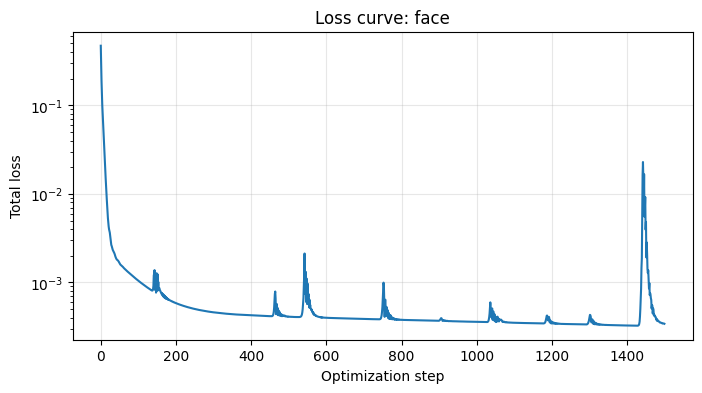

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel('Optimization step')
plt.ylabel('Total loss')
# y axis logarithmic:
plt.yscale('log')
plt.title(f"Loss curve: {loss_mode}")
plt.grid(alpha=0.3)
plt.show()

## 7. Interactive morph-stage slider
Drag the slider to scrub through the precomputed stages. There is intentionally no play/pause control.

In [ ]:
stage_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(frame_arrays) - 1,
    step=1,
    description='Morph stage:',
    continuous_update=True,
    style=SLIDER_STYLE,
    layout=SLIDER_LAYOUT,
)
stage_output = widgets.Output()

def show_morph_stage(change=None):
    frame_index = stage_slider.value
    step = frame_steps[frame_index]
    frame = frame_arrays[frame_index]
    with stage_output:
        clear_output(wait=True)
        plt.figure(figsize=(15, 5))
        for position, (image, title) in enumerate([
            (source_pil, 'Original source'),
            (frame, f'Morph stage {frame_index + 1}/{len(frame_arrays)}\nOptimization step {step}'),
            (target_pil, 'Target'),
        ], start=1):
            plt.subplot(1, 3, position)
            plt.imshow(image)
            plt.title(title)
            plt.axis('off')
        plt.tight_layout()
        plt.show()

stage_slider.observe(show_morph_stage, names='value')
display(stage_slider, stage_output)
show_morph_stage()

IntSlider(value=0, description='Morph stage:', layout=Layout(width='520px'), max=300, style=SliderStyle(descri…

Output()

## 8. Save the final image

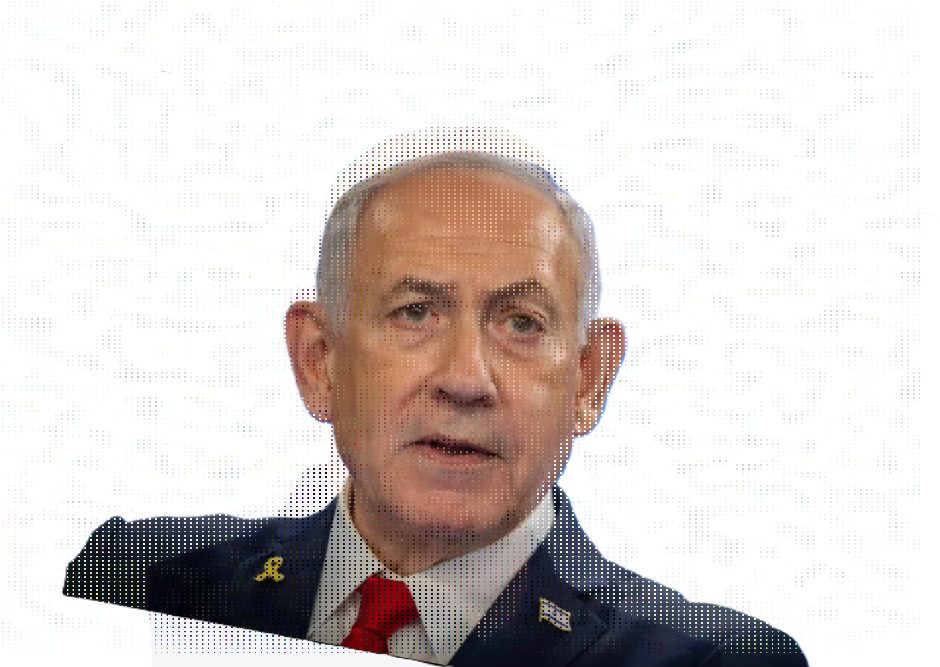

Saved: optimized_face.png


In [ ]:
final_image = Image.fromarray((frame_arrays[-1] * 255).round().astype(np.uint8))
output_path = f"optimized_{loss_mode}.png"
final_image.save(output_path)
display(final_image)
print('Saved:', output_path)